# Прогнозирование свойств композиционных материалов

Проект по заданию МГТУ им. Н. Э. Баумана. Python, pandas, NumPy, matplotlib/seaborn, scikit-learn, MinMaxScaler, Keras/TensorFlow и Flask. Код написан заново.

Обзорные ячейки выполнены по сохранённым результатам. Полное обучение — `train.py`, журнал — `training_log.txt`. Состояние нейросети показано явно; pending означает, что обязательный этап ИНС ещё не выполнен.

## 1. Данные и INNER JOIN

Первая колонка Excel — индекс. В результат попадают только общие индексы двух таблиц.

In [1]:
from pathlib import Path
import json, sys
import pandas as pd
PROJECT = Path.cwd()
sys.path.insert(0, str(PROJECT))
from train import load_data, TARGETS, RATIO
bp, nup, df = load_data()
print('Исходные таблицы:', bp.shape, nup.shape, 'После INNER:', df.shape)
print('Пропуски:', df.isna().sum().sum(), 'Дубликаты:', df.duplicated().sum())
print(df.head(3).to_string())


Исходные таблицы: (1023, 10) (1040, 3) После INNER: (1023, 13)
Пропуски: 0 Дубликаты: 0
   Соотношение матрица-наполнитель  Плотность, кг/м3  модуль упругости, ГПа  Количество отвердителя, м.%  Содержание эпоксидных групп,%_2  Температура вспышки, С_2  Поверхностная плотность, г/м2  Модуль упругости при растяжении, ГПа  Прочность при растяжении, МПа  Потребление смолы, г/м2  Угол нашивки, град  Шаг нашивки  Плотность нашивки
0                         1.857143            2030.0             738.736842                         30.0                        22.267857                100.000000                          210.0                                  70.0                         3000.0                    220.0                 0.0          4.0               57.0
1                         1.857143            2030.0             738.736842                         50.0                        23.750000                284.615385                          210.0                                  70

## 2. EDA

Все гистограммы, boxplot и полная матрица scatter сохранены в `reports/figures`. Номера переменных расшифрованы в `feature_dictionary.csv`. IQR-выброс не обязательно означает ошибку измерения.

In [2]:
stats = pd.read_csv(PROJECT / 'reports/descriptive_statistics.csv', index_col=0)
print(stats[['count', 'mean', 'median', 'min', 'max', 'missing', 'iqr_flags']].to_string())
print(df.corr()[TARGETS].to_string())


                                       count         mean       median          min          max  missing  iqr_flags
Соотношение матрица-наполнитель       1023.0     2.930366     2.906878     0.389403     5.591742        0          6
Плотность, кг/м3                      1023.0  1975.734888  1977.621657  1731.764635  2207.773481        0          9
модуль упругости, ГПа                 1023.0   739.923233   739.664328     2.436909  1911.536477        0          2
Количество отвердителя, м.%           1023.0   110.570769   110.564840    17.740275   198.953207        0         14
Содержание эпоксидных групп,%_2       1023.0    22.244390    22.230744    14.254985    33.000000        0          2
Температура вспышки, С_2              1023.0   285.882151   285.896812   100.000000   413.273418        0          8
Поверхностная плотность, г/м2         1023.0   482.731833   451.864365     0.603740  1399.542362        0          2
Модуль упругости при растяжении, ГПа  1023.0    73.328571    73.

Корреляционная матрица

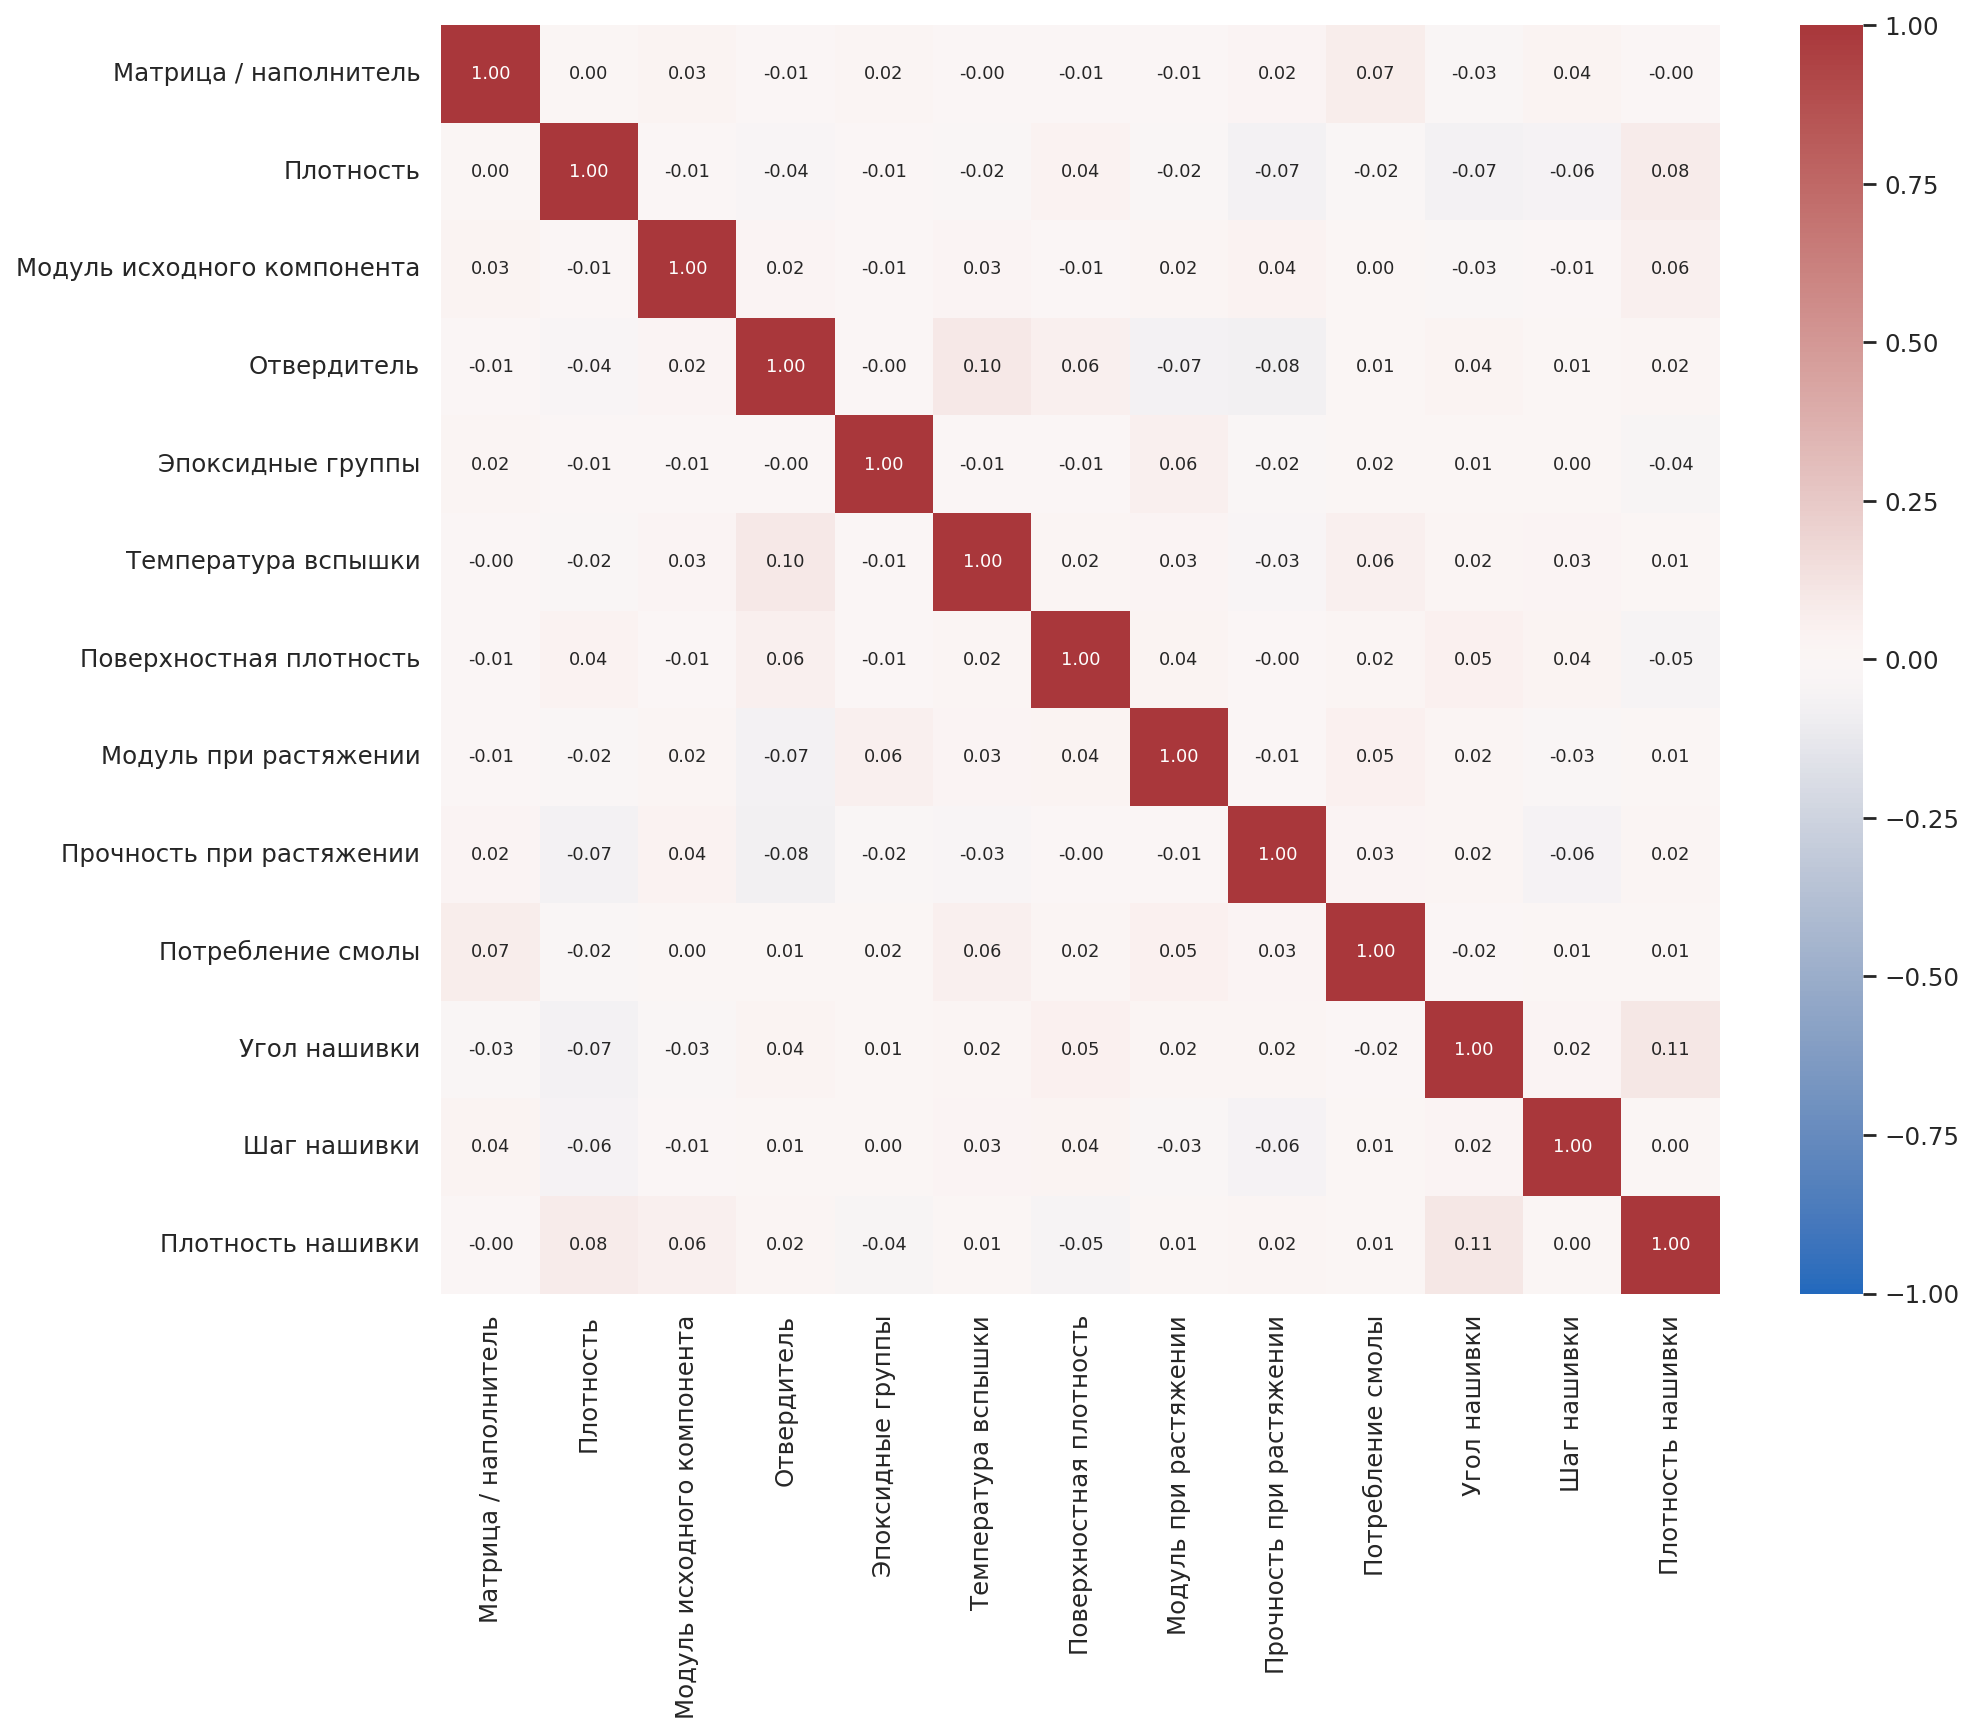

## 3. Разделение и предобработка

716 train и 307 test, random_state=42. IQR-границы вычисляются только по обучающей части каждого CV-блока. Угол 0/90 не удаляется. Test и CV-валидация не фильтруются. MinMaxScaler обучается только на очищенной обучающей части.

In [3]:
manifest = json.loads((PROJECT / 'reports/run_manifest.json').read_text(encoding='utf-8'))
split = json.loads((PROJECT / 'reports/split_indices.json').read_text(encoding='utf-8'))
print('Train/test:', len(split['train']), len(split['test']))
print('Пересечение:', len(set(split['train']) & set(split['test'])))
print(pd.read_csv(PROJECT / 'reports/preprocessing_ranges.csv').to_string(index=False))


Train/test: 716 307
Пересечение: 0
                        feature  iqr_lower_train  iqr_upper_train  train_min_before  train_max_before  train_min_clean  train_max_clean  scaled_min  scaled_max
Соотношение матрица-наполнитель         0.506847         5.372921          0.389403          5.455566         0.547391         5.295842         0.0         1.0
               Плотность, кг/м3      1779.195678      2164.350299       1740.657496       2192.297637      1784.482245      2160.751439         0.0         1.0
          модуль упругости, ГПа      -170.187670      1612.814298          2.436909       1911.536477         2.436909      1572.096042         0.0         1.0
    Количество отвердителя, м.%        37.481020       183.984754         17.740275        198.953207        38.668500       181.828448         0.0         1.0
Содержание эпоксидных групп,%_2        15.446060        28.956850         15.695894         28.955094        15.695894        28.955094         0.0         1.0
     

## 4. Работа с моделями

LinearRegression, Ridge, Lasso, RandomForest, GradientBoosting и контрольный средний прогноз. GridSearchCV с 10 перемешанными блоками; критерий RMSE. Выбор среди пяти моделей основного варианта с IQR по CV. Дополнительный Ridge без IQR — анализ чувствительности. Test не использован для выбора. Train-метрики рассчитаны на всех 716 исходных строках, включая исключённые из fit.

In [4]:
metrics = pd.read_csv(PROJECT / 'reports/model_metrics.csv')
print(metrics[['target', 'model', 'cv_rmse', 'cv_rmse_std', 'train_r2', 'test_r2', 'test_mae', 'test_rmse']].to_string(index=False))
print(json.dumps(manifest['selected_models'], ensure_ascii=False, indent=2))


                              target            model    cv_rmse  cv_rmse_std  train_r2   test_r2   test_mae  test_rmse
Модуль упругости при растяжении, ГПа        DummyMean   3.092476     0.212135  0.000000 -0.016426   2.556417   3.177672
Модуль упругости при растяжении, ГПа LinearRegression   3.111932     0.199370  0.018434 -0.027470   2.569067   3.194889
Модуль упругости при растяжении, ГПа            Ridge   3.093140     0.210427  0.007056 -0.018882   2.560377   3.181510
Модуль упругости при растяжении, ГПа            Lasso   3.093066     0.213681 -0.000187 -0.020048   2.560455   3.183330
Модуль упругости при растяжении, ГПа     RandomForest   3.107805     0.196321  0.130887 -0.049191   2.596242   3.228484
Модуль упругости при растяжении, ГПа GradientBoosting   3.104244     0.220292  0.033643 -0.031373   2.584322   3.200951
Модуль упругости при растяжении, ГПа  RidgeWithoutIQR   3.092863     0.209901  0.006196 -0.014079   2.554635   3.174002
       Прочность при растяжении, МПа    

R² на независимой тестовой выборке

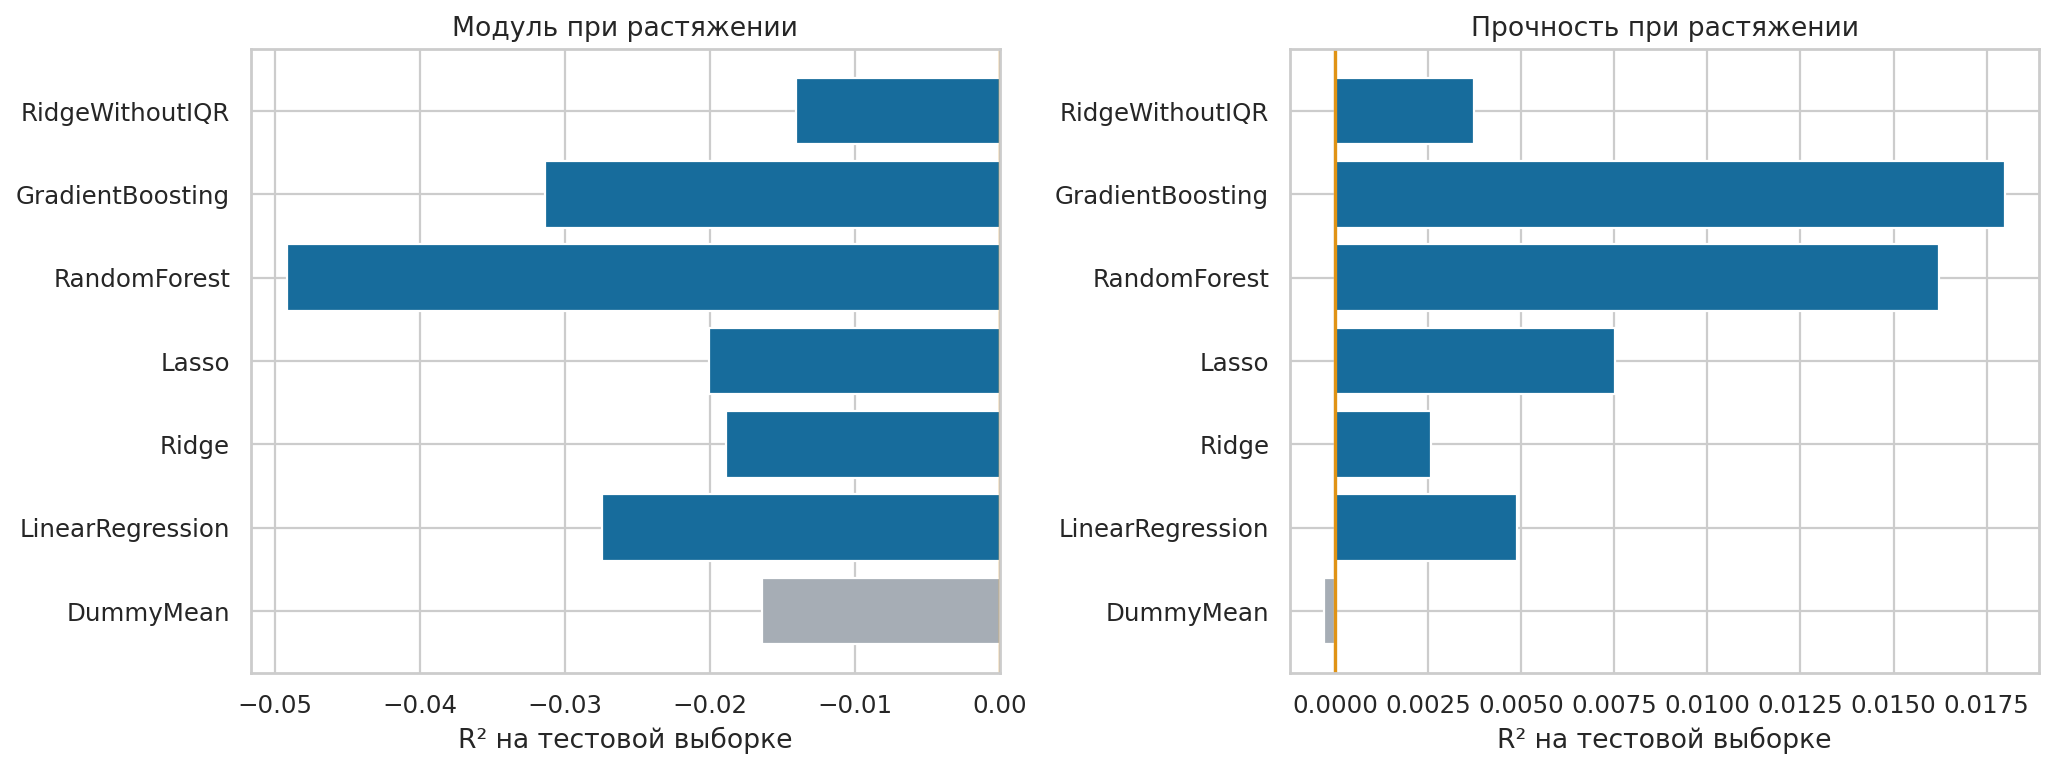

## 5. ИНС на Keras / TensorFlow

Цель — соотношение матрица–наполнитель. 12 входов включают известные или желаемые механические свойства. Это обратная регрессия, не оптимизация рецепта. Архитектуры (16,8) и (32,16), ReLU, Adam, линейный выход. Выбор регуляризации и эпохи по отдельной validation внутри train; test не используется.

In [5]:
print(json.dumps(manifest['neural_network'], ensure_ascii=False, indent=2))
if manifest['neural_network'].get('status') == 'trained':
    print(pd.read_csv(PROJECT / 'reports/neural_candidates.csv').to_string(index=False))
    print(pd.read_csv(PROJECT / 'reports/neural_metrics.csv').to_string(index=False))
else:
    print('Обучение Keras ещё не выполнено. Запустите полный train.py, например в Google Colab.')


{
  "hidden_layers": "(16, 8)",
  "alpha": 0.001,
  "best_epoch": 70,
  "epochs_run": 90,
  "validation_rmse": 0.7794127666005525,
  "input_features": 12,
  "activation": "relu",
  "optimizer": "adam",
  "fit_n_before_iqr": 572,
  "fit_n_after_iqr": 523,
  "validation_n": 144,
  "test_n": 307,
  "early_stopping_patience": 20,
  "framework": "TensorFlow 2.21.0 / Keras 3.15.1",
  "portable_max_abs_error": 5.522680921465906e-07,
  "metrics": [
    {
      "model": "KerasMLP",
      "train_r2": 0.03519813656583526,
      "train_mae": 0.709538866777772,
      "train_rmse": 0.8908714825041666,
      "test_r2": -0.040153867677258814,
      "test_mae": 0.7742187538513766,
      "test_rmse": 0.9442216562675536
    },
    {
      "model": "DummyMean",
      "train_r2": -0.00030913037198931903,
      "train_mae": 0.719068835696763,
      "train_rmse": 0.9071165836890518,
      "test_r2": -0.00023491889613325156,
      "test_mae": 0.7525352519182201,
      "test_rmse": 0.9259257646379433
    }
  ]

Ошибка обучения и валидации Keras

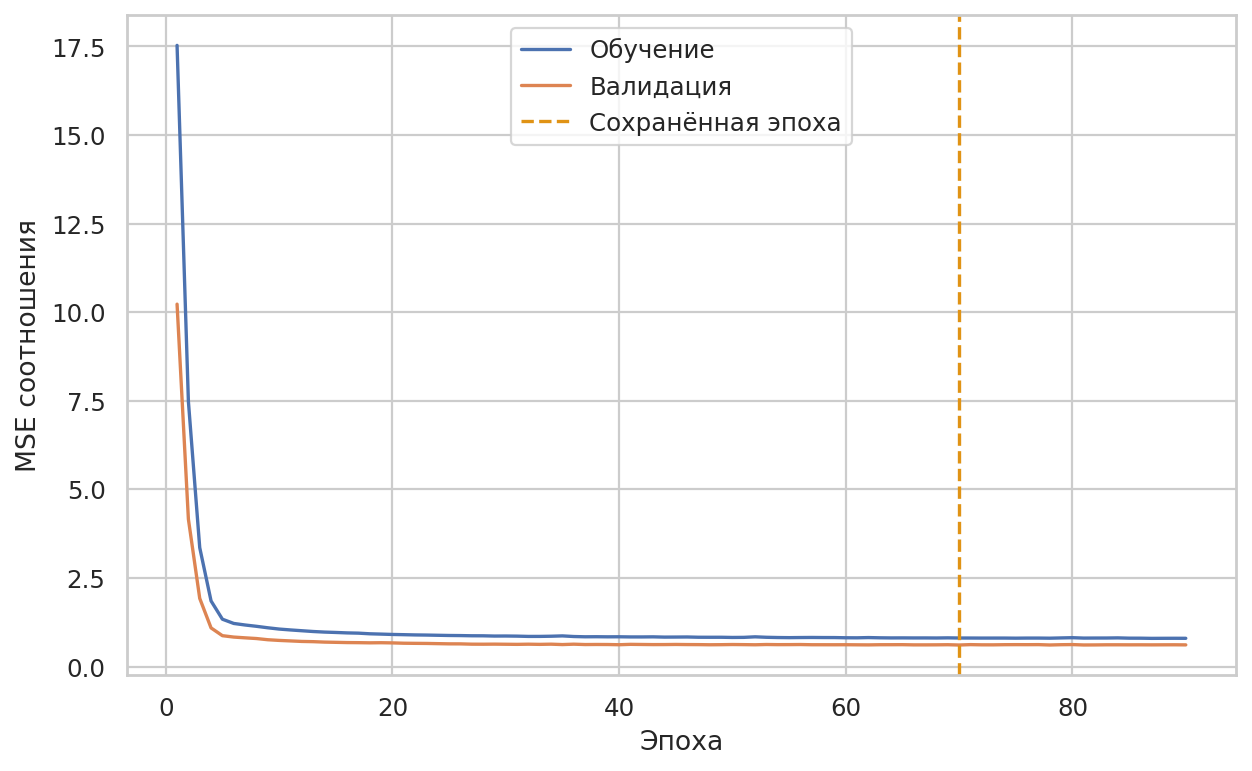

## 6. Приложение и проверка

Интерфейс Flask; его зависимости включены в проект. Прогнозы JSON проверяются против исходных sklearn/Keras-моделей. При применении не требуется устанавливать TensorFlow. Пример по медианным входам — демонстрация расчёта, не оценка ошибки.

In [6]:
from predictor import load_bundle, predict_request
bundle = load_bundle(PROJECT / 'models/portable_models.json')
print(predict_request(bundle, 'properties', {f['name']: f['default'] for f in bundle['features']}))
if bundle['ratio_model'] is not None:
    print(predict_request(bundle, 'ratio', {f['name']: f['default'] for f in bundle['ratio_features']}))
print((PROJECT / 'reports/app_verification.json').read_text(encoding='utf-8'))


{'Модуль упругости при растяжении, ГПа': 73.16501508986109, 'Прочность при растяжении, МПа': 2487.7766098232455}
{'Соотношение матрица-наполнитель': 2.9944486082504325}
{
  "status": "passed",
  "checks": 40,
  "comparison": "Прогнозы sklearn/Keras и JSON через Flask",
  "dependencies": "Flask и зависимости включены в _vendor; установка пользователем не нужна"
}


## Выводы

Сравнивать модели нужно с простым средним и учитывать неопределённость по блокам. R² около нуля или ниже указывает на слабое качество на данном разделении. Низкие линейные корреляции не доказывают отсутствия любых нелинейных связей. Для инженерного использования необходимы уточнение данных и дополнительная валидация.

Повторное обучение: `python train.py`, затем `python verify.py` и `python make_research_notebook.py`. Для Google Colab используйте `START_COLAB.ipynb`.